# 04 - Extensions: what changes the Faber-Jackson slope?

Notebook 03 found $n \approx 1.9$ (forward fit) to $2.8$ (inverse fit), well below the classic $n = 4$. Here we test three possible explanations that were not suggested in the brief:

1. **Luminosity / dispersion range:** is the relation steeper for the most massive galaxies, as in the original Faber & Jackson sample?
2. **Environment:** do early types in clusters follow the same relation as those in the GAMA field and group regions?
3. **Rotation:** do slow rotators (supported by random motions) and fast rotators (with some rotational support) follow different relations?

All fits use the same 768-galaxy early-type sample from notebook 02 and the same method as notebook 03 (forward fit of $M_r$ against $\log\sigma$, with $n = -\text{slope}/2.5$).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

early = pd.read_csv('../data/processed/sample_early_types.csv')
early['log_sigma'] = np.log10(early['sigma_re'])

all_fit = stats.linregress(early['log_sigma'], early['m_r'])
print('Early-type galaxies:', len(early))
print(f'Whole sample: n = {-all_fit.slope/2.5:.2f} +/- {all_fit.stderr/2.5:.2f}')

Early-type galaxies: 768
Whole sample: n = 1.88 +/- 0.05


## 1. Is the relation steeper for high-dispersion galaxies?

The original FJ sample was mostly bright, massive ellipticals. If the relation curves (shallower for fainter galaxies), then our sample, which includes many lower-mass galaxies, would give a smaller $n$.

How we split the sample matters. In a forward fit, $M_r$ is the y variable. If we keep only galaxies brighter than some magnitude, we cut the cloud of points horizontally, which removes galaxies below the line at low $\sigma$ and artificially flattens the slope. This is a selection bias. Splitting by $\sigma$ (the x variable) does not have this problem, so we split at the median $\sigma$.

In [2]:
sigma_split = early['sigma_re'].median()
high = early[early['sigma_re'] > sigma_split]
low = early[early['sigma_re'] <= sigma_split]

high_fit = stats.linregress(high['log_sigma'], high['m_r'])
low_fit = stats.linregress(low['log_sigma'], low['m_r'])

print(f'Median sigma: {sigma_split:.0f} km/s')
print(f'High sigma ({len(high)} galaxies): n = {-high_fit.slope/2.5:.2f} +/- {high_fit.stderr/2.5:.2f}')
print(f'Low sigma  ({len(low)} galaxies): n = {-low_fit.slope/2.5:.2f} +/- {low_fit.stderr/2.5:.2f}')

Median sigma: 150 km/s
High sigma (384 galaxies): n = 2.08 +/- 0.15
Low sigma  (384 galaxies): n = 1.54 +/- 0.10


For comparison, here is what happens if we wrongly split by magnitude instead:

In [3]:
bright = early[early['m_r'] < -21.5]
bright_fit = stats.linregress(bright['log_sigma'], bright['m_r'])

print(f'Brighter than M_r = -21.5 ({len(bright)} galaxies): n = {-bright_fit.slope/2.5:.2f} +/- {bright_fit.stderr/2.5:.2f}')

Brighter than M_r = -21.5 (229 galaxies): n = 0.76 +/- 0.09


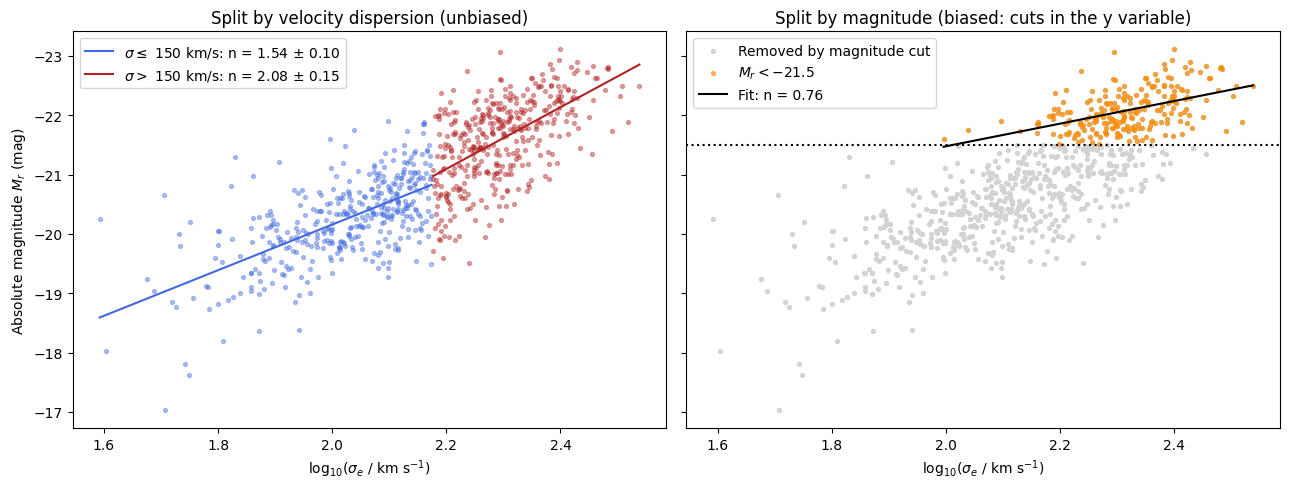

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

ax = axes[0]
for sub, f, colour, label in [(low, low_fit, 'royalblue', f'$\\sigma \\leq$ {sigma_split:.0f} km/s'),
                              (high, high_fit, 'firebrick', f'$\\sigma >$ {sigma_split:.0f} km/s')]:
    x = np.linspace(sub['log_sigma'].min(), sub['log_sigma'].max(), 100)
    ax.scatter(sub['log_sigma'], sub['m_r'], s=8, color=colour, alpha=0.4)
    ax.plot(x, f.slope * x + f.intercept, color=colour, label=f'{label}: n = {-f.slope/2.5:.2f} $\\pm$ {f.stderr/2.5:.2f}')
ax.set_title('Split by velocity dispersion (unbiased)')
ax.set_xlabel(r'log$_{10}$($\sigma_e$ / km s$^{-1}$)')
ax.set_ylabel(r'Absolute magnitude $M_r$ (mag)')
ax.legend()

ax = axes[1]
x = np.linspace(bright['log_sigma'].min(), bright['log_sigma'].max(), 100)
ax.scatter(early['log_sigma'], early['m_r'], s=8, color='lightgrey', label='Removed by magnitude cut')
ax.scatter(bright['log_sigma'], bright['m_r'], s=8, color='darkorange', alpha=0.6, label='$M_r < -21.5$')
ax.plot(x, bright_fit.slope * x + bright_fit.intercept, color='black', label=f'Fit: n = {-bright_fit.slope/2.5:.2f}')
ax.axhline(-21.5, color='black', linestyle=':')
ax.set_title('Split by magnitude (biased: cuts in the y variable)')
ax.set_xlabel(r'log$_{10}$($\sigma_e$ / km s$^{-1}$)')
ax.legend()

axes[0].invert_yaxis()
plt.tight_layout()
plt.savefig('../figures/07_fj_sigma_split.png', dpi=150)
plt.show()

## 2. Does environment matter?

SAMI observed galaxies in two kinds of region: the GAMA fields (isolated galaxies and groups) and eight dense galaxy clusters. Galaxies in clusters are thought to have formed earlier and stopped forming stars sooner, so their stars are older.

We fit each environment separately, then look at the residuals from the whole-sample fit (observed $M_r$ minus the fit's prediction). A positive mean residual means galaxies in that environment are fainter than average at the same $\sigma$. We do the same for the stellar-mass form ($\log\sigma$ against $\log M_*$) to see whether any difference is in luminosity or in mass.

In [5]:
mass_fit = stats.linregress(early['mstar'], early['log_sigma'])
early['lum_residual'] = early['m_r'] - (all_fit.slope * early['log_sigma'] + all_fit.intercept)
early['mass_residual'] = early['log_sigma'] - (mass_fit.slope * early['mstar'] + mass_fit.intercept)

env_rows = []
for env in ['GAMA', 'Cluster']:
    sub = early[early['environment'] == env]
    f = stats.linregress(sub['log_sigma'], sub['m_r'])
    env_rows.append({'environment': env,
                     'N': len(sub),
                     'n_forward': round(-f.slope / 2.5, 2),
                     'n_forward_err': round(f.stderr / 2.5, 2),
                     'mean_lum_residual_mag': round(sub['lum_residual'].mean(), 3),
                     'lum_residual_err': round(sub['lum_residual'].std() / np.sqrt(len(sub)), 3),
                     'mean_mass_residual_dex': round(sub['mass_residual'].mean(), 3),
                     'mass_residual_err': round(sub['mass_residual'].std() / np.sqrt(len(sub)), 3),
                     'median_log_mstar': round(sub['mstar'].median(), 2)})

env_results = pd.DataFrame(env_rows)
env_results

,environment,N,n_forward,n_forward_err,mean_lum_residual_mag,lum_residual_err,mean_mass_residual_dex,mass_residual_err,median_log_mstar
0,GAMA,414,2.15,0.07,-0.131,0.027,-0.005,0.004,10.64
1,Cluster,354,1.47,0.06,0.154,0.029,0.006,0.005,10.34


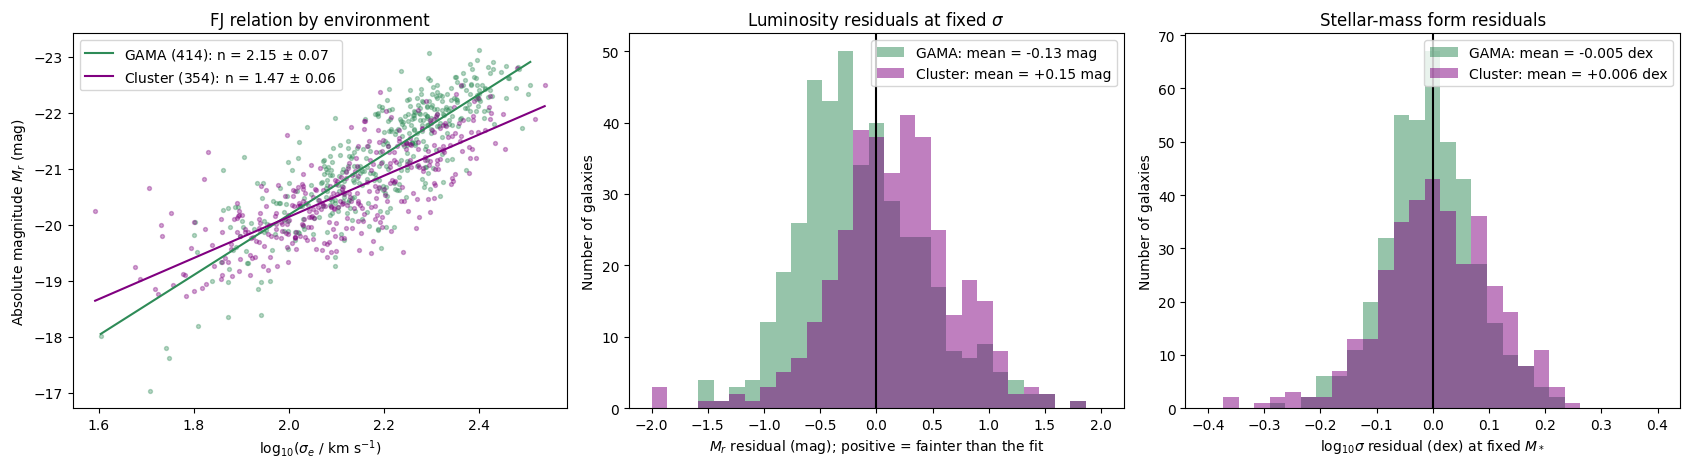

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

ax = axes[0]
for env, colour in [('GAMA', 'seagreen'), ('Cluster', 'purple')]:
    sub = early[early['environment'] == env]
    f = stats.linregress(sub['log_sigma'], sub['m_r'])
    x = np.linspace(sub['log_sigma'].min(), sub['log_sigma'].max(), 100)
    ax.scatter(sub['log_sigma'], sub['m_r'], s=8, color=colour, alpha=0.35)
    ax.plot(x, f.slope * x + f.intercept, color=colour, label=f'{env} ({len(sub)}): n = {-f.slope/2.5:.2f} $\\pm$ {f.stderr/2.5:.2f}')
ax.invert_yaxis()
ax.set_xlabel(r'log$_{10}$($\sigma_e$ / km s$^{-1}$)')
ax.set_ylabel(r'Absolute magnitude $M_r$ (mag)')
ax.set_title('FJ relation by environment')
ax.legend()

bins_lum = np.linspace(-2, 2, 30)
bins_mass = np.linspace(-0.4, 0.4, 30)
for env, colour in [('GAMA', 'seagreen'), ('Cluster', 'purple')]:
    sub = early[early['environment'] == env]
    axes[1].hist(sub['lum_residual'], bins=bins_lum, alpha=0.5, color=colour, label=f'{env}: mean = {sub["lum_residual"].mean():+.2f} mag')
    axes[2].hist(sub['mass_residual'], bins=bins_mass, alpha=0.5, color=colour, label=f'{env}: mean = {sub["mass_residual"].mean():+.3f} dex')

axes[1].axvline(0, color='black')
axes[1].set_xlabel(r'$M_r$ residual (mag); positive = fainter than the fit')
axes[1].set_ylabel('Number of galaxies')
axes[1].set_title('Luminosity residuals at fixed $\\sigma$')
axes[1].legend()

axes[2].axvline(0, color='black')
axes[2].set_xlabel(r'log$_{10}\sigma$ residual (dex) at fixed $M_*$')
axes[2].set_ylabel('Number of galaxies')
axes[2].set_title('Stellar-mass form residuals')
axes[2].legend()

plt.tight_layout()
plt.savefig('../figures/08_fj_environment.png', dpi=150)
plt.show()

## 3. Slow rotators vs fast rotators

The spin parameter $\lambda_{R_e}$ (column `lambdar_re`) measures how much a galaxy is supported by ordered rotation (close to 1) compared with random motions (close to 0). Flatter galaxies (higher ellipticity $\varepsilon$) can rotate more, so the dividing line depends on $\varepsilon$. We use the definition from Cappellari (2016): a galaxy is a slow rotator if

$$\lambda_{R_e} < 0.08 + \varepsilon/4 \quad \text{and} \quad \varepsilon < 0.4,$$

and a fast rotator otherwise. Galaxies without a measured $\lambda_{R_e}$ are left out of this test.

In [7]:
rot = early.dropna(subset=['lambdar_re', 'ellip']).copy()
rot['slow'] = (rot['lambdar_re'] < 0.08 + rot['ellip'] / 4) & (rot['ellip'] < 0.4)

slow = rot[rot['slow']]
fast = rot[~rot['slow']]

print('Galaxies with lambda_R measured:', len(rot), 'of', len(early))
print('Slow rotators:', len(slow))
print('Fast rotators:', len(fast))
print()
print('Morphology of slow rotators:', slow['morph'].value_counts().to_dict())
print('Morphology of fast rotators:', fast['morph'].value_counts().to_dict())
print()

slow_fit = stats.linregress(slow['log_sigma'], slow['m_r'])
fast_fit = stats.linregress(fast['log_sigma'], fast['m_r'])
print(f'Slow rotators: n = {-slow_fit.slope/2.5:.2f} +/- {slow_fit.stderr/2.5:.2f}, median M_r = {slow["m_r"].median():.2f}')
print(f'Fast rotators: n = {-fast_fit.slope/2.5:.2f} +/- {fast_fit.stderr/2.5:.2f}, median M_r = {fast["m_r"].median():.2f}')

Galaxies with lambda_R measured: 676 of 768
Slow rotators: 145
Fast rotators: 531

Morphology of slow rotators: {'E': 75, 'E/S0': 47, 'S0': 23}
Morphology of fast rotators: {'S0': 271, 'E/S0': 142, 'E': 118}

Slow rotators: n = 2.17 +/- 0.09, median M_r = -21.63
Fast rotators: n = 1.76 +/- 0.05, median M_r = -20.98


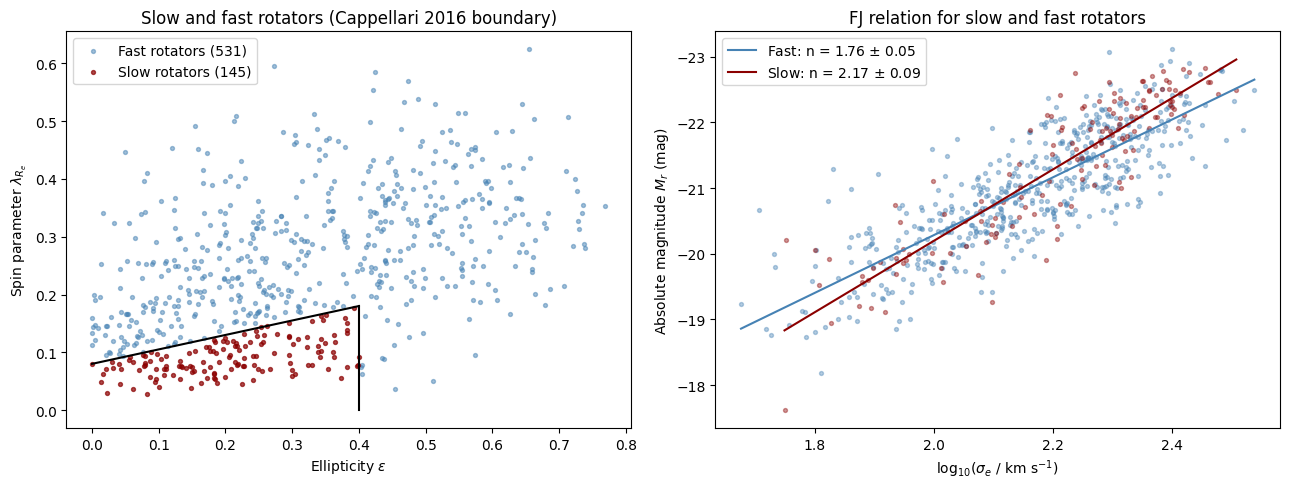

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
e_line = np.linspace(0, 0.4, 50)
ax.scatter(fast['ellip'], fast['lambdar_re'], s=8, color='steelblue', alpha=0.5, label=f'Fast rotators ({len(fast)})')
ax.scatter(slow['ellip'], slow['lambdar_re'], s=8, color='darkred', alpha=0.7, label=f'Slow rotators ({len(slow)})')
ax.plot(e_line, 0.08 + e_line / 4, color='black')
ax.plot([0.4, 0.4], [0, 0.08 + 0.4 / 4], color='black')
ax.set_xlabel(r'Ellipticity $\varepsilon$')
ax.set_ylabel(r'Spin parameter $\lambda_{R_e}$')
ax.set_title('Slow and fast rotators (Cappellari 2016 boundary)')
ax.legend()

ax = axes[1]
for sub, f, colour, label in [(fast, fast_fit, 'steelblue', 'Fast'), (slow, slow_fit, 'darkred', 'Slow')]:
    x = np.linspace(sub['log_sigma'].min(), sub['log_sigma'].max(), 100)
    ax.scatter(sub['log_sigma'], sub['m_r'], s=8, color=colour, alpha=0.4)
    ax.plot(x, f.slope * x + f.intercept, color=colour, label=f'{label}: n = {-f.slope/2.5:.2f} $\\pm$ {f.stderr/2.5:.2f}')
ax.invert_yaxis()
ax.set_xlabel(r'log$_{10}$($\sigma_e$ / km s$^{-1}$)')
ax.set_ylabel(r'Absolute magnitude $M_r$ (mag)')
ax.set_title('FJ relation for slow and fast rotators')
ax.legend()

plt.tight_layout()
plt.savefig('../figures/09_fj_rotators.png', dpi=150)
plt.show()

## 4. Save the results

In [9]:
ext = pd.DataFrame([
    {'test': 'All early types', 'N': len(early), 'n_forward': -all_fit.slope / 2.5, 'n_forward_err': all_fit.stderr / 2.5},
    {'test': f'sigma > {sigma_split:.0f} km/s', 'N': len(high), 'n_forward': -high_fit.slope / 2.5, 'n_forward_err': high_fit.stderr / 2.5},
    {'test': f'sigma <= {sigma_split:.0f} km/s', 'N': len(low), 'n_forward': -low_fit.slope / 2.5, 'n_forward_err': low_fit.stderr / 2.5},
    {'test': 'M_r < -21.5 (biased cut)', 'N': len(bright), 'n_forward': -bright_fit.slope / 2.5, 'n_forward_err': bright_fit.stderr / 2.5},
    {'test': 'GAMA', 'N': env_results.loc[0, 'N'], 'n_forward': env_results.loc[0, 'n_forward'], 'n_forward_err': env_results.loc[0, 'n_forward_err']},
    {'test': 'Cluster', 'N': env_results.loc[1, 'N'], 'n_forward': env_results.loc[1, 'n_forward'], 'n_forward_err': env_results.loc[1, 'n_forward_err']},
    {'test': 'Slow rotators', 'N': len(slow), 'n_forward': -slow_fit.slope / 2.5, 'n_forward_err': slow_fit.stderr / 2.5},
    {'test': 'Fast rotators', 'N': len(fast), 'n_forward': -fast_fit.slope / 2.5, 'n_forward_err': fast_fit.stderr / 2.5},
]).round(2)

ext.to_csv('../data/processed/fj_extension_results.csv', index=False)
env_results.to_csv('../data/processed/fj_environment_results.csv', index=False)
ext

,test,N,n_forward,n_forward_err
0,All early types,768,1.88,0.05
1,sigma > 150 km/s,384,2.08,0.15
2,sigma <= 150 km/s,384,1.54,0.10
3,M_r < -21.5 (biased cut),229,0.76,0.09
4,GAMA,414,2.15,0.07
5,Cluster,354,1.47,0.06
6,Slow rotators,145,2.17,0.09
7,Fast rotators,531,1.76,0.05


## 5. Summary

| Test | N | $n$ (forward fit) |
|---|---|---|
| All early types | 768 | 1.88 ± 0.05 |
| $\sigma > 150$ km/s | 384 | 2.08 ± 0.15 |
| $\sigma \leq 150$ km/s | 384 | 1.54 ± 0.10 |
| GAMA (field/group) | 414 | 2.15 ± 0.07 |
| Cluster | 354 | 1.47 ± 0.06 |
| Slow rotators | 145 | 2.17 ± 0.09 |
| Fast rotators | 531 | 1.76 ± 0.05 |

**1. Dispersion range.** The relation is steeper for high-$\sigma$ galaxies ($n \approx 2.1$) than for low-$\sigma$ galaxies ($n \approx 1.5$), so it is not a single straight line: it curves, becoming steeper for the most massive galaxies. This is one reason our whole-sample $n$ is lower than the $n \approx 4$ found from bright ellipticals. Cutting the sample by magnitude instead gives $n \approx 0.8$, which shows how selecting on the y variable biases a fit. Magnitude-limited surveys have the same problem, so it matters for any published comparison.

**2. Environment.** At the same $\sigma$, cluster early types are about 0.28 mag fainter than GAMA early types (mean residuals +0.15 and −0.13 mag, each with an error of about 0.03 mag). In the stellar-mass form the two environments agree (mean residuals within 0.01 dex). So at fixed $\sigma$, cluster galaxies have the same stellar mass but less light, meaning a higher mass-to-light ratio. This fits the idea that cluster galaxies formed their stars earlier and stopped sooner, so their stellar populations are older and dimmer. A difference in how the two input catalogues measured photometry could also contribute. The different slopes are harder to interpret: the cluster sample has lower masses on average (median $\log M_* = 10.34$ vs 10.64), and test 1 shows the slope depends on mass range.

**3. Rotation.** Slow rotators follow a steeper relation ($n \approx 2.2$) than fast rotators ($n \approx 1.8$). Most slow rotators are ellipticals, and most fast rotators are S0s and E/S0s, which agrees with the S0s having the shallowest slope in notebook 03. However, slow rotators are also brighter (median $M_r = -21.6$ vs $-21.0$), so part of this difference may be the same curvature seen in test 1.

Slow rotators are usually explained as the products of several mergers, which scramble ordered rotation into random motions. Fast rotators keep a disk-like structure from a quieter history. The fact that the FJ slope depends on rotation, mass range and environment suggests the relation is not one universal law. Instead, it reflects different formation histories, and the most massive, merger-built slow rotators come closest to the classic steep relation.